# Instituto Superior de Engenharia do Porto (ISEP)
## Departamento de Engenharia Electrotécnica (DEE)
### Unidade Curricular: Sinais e Sistemas (SINSI) - Licenciatura em Engenharia Electrotécnica e de Computadores (LEEC)

---
# Folha Prática TP08a: Análise de Sistemas LIT no Domínio da Frequência
### Resolução Analítica Rigorosa, Enquadramento Teórico e Simulação em Python
**Docente Responsável:** Equipa Docente de Sinais e Sistemas  
**Tema:** Sistemas Lineares e Invariantes no Tempo (LIT) Contínuos, Equações Diferenciais Lineares, Resposta em Frequência $H(j\omega)$, Resposta Impulsional $h(t)$, Convolução Espectral e Resposta Temporal $y(t)$.

---

### Objetivos Pedagógicos desta Sessão:
1. **Compreensão Teórico-Conceptual:** Dominar a representação e caracterização de sistemas LIT em tempo contínuo descritos por Equações Diferenciais Lineares de Coeficientes Constantes (EDLCC) através da Transformada de Fourier de Tempo Contínuo (CTFT).
2. **Propriedade da Diferenciação no Tempo:** Compreender a transposição formal do operador diferencial $\frac{d}{dt}$ para o operador algébrico multiplicativo $(j\omega)$, simplificando equações diferenciais integro-diferenciais em equações puramente algébricas.
3. **Caracterização Espectral do Sistema:** Determinar analiticamente a **Resposta em Frequência** $H(j\omega) = \frac{Y(j\omega)}{X(j\omega)}$ e analisar a sua magnitude $|H(j\omega)|$, fase $\angle H(j\omega)$, ganho DC ($0\text{ rad/s}$) e frequência de corte a $-3\text{ dB}$.
4. **Comportamento Impulsional, Causalidade e Estabilidade:** Extrair a resposta ao impulso $h(t) = \mathcal{F}^{-1}\{H(j\omega)\}$ e relacionar a estabilidade BIBO (*Bounded-Input Bounded-Output*) com a convergência absoluta $\int_{-\infty}^{+\infty}|h(t)|dt < \infty$ e a localização dos polos.
5. **Cálculo da Saída por Frações Parciais:** Calcular a resposta espectral de saída $Y(j\omega) = H(j\omega)X(j\omega)$ e efetuar a inversão analítica via decomposição em frações simples (resíduos de Heaviside) para obter a resposta temporal exata $y(t)$.
6. **Validação Cruzada Computacional:** Implementar rotinas robustas em Python utilizando computação simbólica (`SymPy`), modelagem e simulação de sistemas dinâmicos (`SciPy`) e visualização avançada com diagramas de Bode e respostas temporais (`Matplotlib`).

## 1. Fundamentos Teóricos: Sistemas LIT e a Transformada de Fourier

---

### 1.1. Sistemas LIT Descritos por Equações Diferenciais Lineares de Coeficientes Constantes (EDLCC)
Em Engenharia Electrotécnica, grande parte dos subsistemas analógicos essenciais - como filtros passivos e ativos $RLC$, circuitos amplificadores operacionais, motores de corrente contínua e linhas de transmissão elétricas - são modelados por equações diferenciais lineares de coeficientes constantes de ordem $N$:
$$\sum_{k=0}^{N} a_k \frac{d^k y(t)}{dt^k} = \sum_{m=0}^{M} b_m \frac{d^m x(t)}{dt^m}$$

onde:
* $x(t)$ representa o sinal de excitação (entrada);
* $y(t)$ representa o sinal de resposta (saída);
* $a_k$ e $b_m$ são parâmetros físicos reais do sistema (resistências, indutâncias, capacidades, constantes mecânicas);
* O sistema é considerado **causal** e em **repouso inicial** para análise da sua resposta forçada permanente.

---

### 1.2. A Propriedade da Diferenciação no Tempo da Transformada de Fourier
A Transformada de Fourier em Tempo Contínuo (CTFT) de uma função $f(t)$ absolutamente integrável é definida por:
$$F(j\omega) = \mathcal{F}\{f(t)\} = \int_{-\infty}^{+\infty} f(t) e^{-j\omega t} \, dt$$

Diferenciando no tempo a equação de síntese $f(t) = \frac{1}{2\pi} \int_{-\infty}^{+\infty} F(j\omega) e^{j\omega t} d\omega$ sob o sinal da integral, obtém-se:
$$\frac{d f(t)}{dt} = \frac{1}{2\pi} \int_{-\infty}^{+\infty} \left[ j\omega F(j\omega) \right] e^{j\omega t} \, d\omega$$

Generalizando por indução para a $n$-ésima derivada:
$$\boxed{\frac{d^n f(t)}{dt^n} \stackrel{\mathcal{F}}{\longleftrightarrow} (j\omega)^n F(j\omega)}$$

> **Interpretação Operacional:** No domínio da frequência, a operação temporal de derivação é mapeada numa multiplicação direta pelo termo imaginário $j\omega$. Isto converte operadores diferenciais complexos em polinómios algébricos elementares.

---

### 1.3. Função de Transferência / Resposta em Frequência $H(j\omega)$
Aplicando a linearidade e a propriedade da diferenciação a ambos os membros da EDLCC:
$$\sum_{k=0}^{N} a_k (j\omega)^k Y(j\omega) = \sum_{m=0}^{M} b_m (j\omega)^m X(j\omega)$$

Colocando $Y(j\omega)$ e $X(j\omega)$ em evidência:
$$Y(j\omega) \left[ \sum_{k=0}^{N} a_k (j\omega)^k \right] = X(j\omega) \left[ \sum_{m=0}^{M} b_m (j\omega)^m \right]$$

Definindo a **Resposta em Frequência** $H(j\omega)$ como a razão entre as transformadas de Fourier da saída e da entrada:
$$\boxed{H(j\omega) \triangleq \frac{Y(j\omega)}{X(j\omega)} = \frac{\displaystyle \sum_{m=0}^{M} b_m (j\omega)^m}{\displaystyle \sum_{k=0}^{N} a_k (j\omega)^k}}$$

$H(j\omega)$ é uma função complexa da frequência contínua $\omega$ (expressa em rad/s), caracterizada pela sua magnitude e pelo seu desfasamento:
$$H(j\omega) = |H(j\omega)| e^{j \angle H(j\omega)}$$
* **Módulo $|H(j\omega)|$:** fator de amplificação ou atenuação aplicado a cada componente espectral de frequência $\omega$.
* **Fase $\angle H(j\omega)$:** avanço ou atraso de fase imposto à componente espectral de frequência $\omega$.

---

### 1.4. Resposta Impulsional $h(t)$, Causalidade e Estabilidade BIBO
A resposta impulsional $h(t)$ é a saída do sistema quando a excitação é um impulso unitário de Dirac $x(t) = \delta(t)$.
Como $\mathcal{F}\{\delta(t)\} = 1$:
$$Y(j\omega) = H(j\omega) \cdot 1 = H(j\omega) \implies \boxed{h(t) = \mathcal{F}^{-1}\{H(j\omega)\} = \frac{1}{2\pi} \int_{-\infty}^{+\infty} H(j\omega) e^{j\omega t} \, d\omega}$$

* **Causalidade:** O sistema é causal se e só se $h(t) = 0, \quad \forall t < 0$.
* **Estabilidade BIBO (*Bounded-Input Bounded-Output*):** O sistema é BIBO-estável se e só se a resposta impulsional for absolutamente integrável:
$$\int_{-\infty}^{+\infty} |h(t)| \, dt < \infty$$
No plano complexo da frequência generalizada $s = \sigma + j\omega$ (Transformada de Laplace), isto equivale a dizer que **todos os polos do sistema têm parte real estritamente negativa** ($\text{Re}\{p_k\} < 0$), situando-se no semiplano esquerdo (SPE). Quando esta condição se verifica, o eixo imaginário $s = j\omega$ pertence à Região de Convergência (ROC) e $H(j\omega) = \left. H(s) \right|_{s = j\omega}$.

---

### 1.5. Propriedade da Convolução e Cálculo da Saída
No domínio do tempo, a resposta de qualquer sistema LIT contínuo é dada pela integral de convolução:
$$y(t) = x(t) * h(t) = \int_{-\infty}^{+\infty} x(\tau) h(t - \tau) \, d\tau$$

No domínio da frequência, a integral de convolução traduz-se no produto direto das respetivas transformadas de Fourier:
$$\boxed{Y(j\omega) = H(j\omega) \cdot X(j\omega)}$$

A recuperação da saída temporal $y(t)$ faz-se pela transformada inversa:
$$y(t) = \mathcal{F}^{-1}\{Y(j\omega)\} = \mathcal{F}^{-1}\{H(j\omega) X(j\omega)\}$$

---

### 1.6. Par Canónico de Fourier e Decomposição em Frações Parciais
Um par canónico fundamental na teoria de sinais contínuos é:
$$\boxed{e^{-at} u(t) \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{1}{j\omega + a}, \quad \text{para } a > 0}$$

Quando $Y(j\omega)$ é uma função racional própria em $j\omega$ com polos simples $p_k = -a_k$ ($a_k > 0$):
$$Y(j\omega) = \frac{P(j\omega)}{\prod_{k=1}^{N} (j\omega + a_k)} = \sum_{k=1}^{N} \frac{A_k}{j\omega + a_k}$$

Os resíduos $A_k$ são calculados com o **Método da Cobertura de Heaviside**:
$$A_k = \lim_{j\omega \to -a_k} \left[ (j\omega + a_k) Y(j\omega) \right]$$

Aplicando a linearidade da transformada inversa:
$$y(t) = \sum_{k=1}^{N} A_k e^{-a_k t} u(t)$$

---

### 1.7. Equivalência Eletrotécnica: Filtro Passa-Baixo RC de 1ª Ordem
Consideremos um circuito analógico de 1ª ordem composto por uma resistência $R$ e um condensador $C$ alimentado por uma fonte de tensão $v_{in}(t)$ através de um amplificador não-inversor com ganho estático $K$:
$$RC \frac{dv_o(t)}{dt} + v_o(t) = K v_{in}(t)$$

Fazendo a constante de tempo $\tau = RC = 1\text{ s}$ e ganho $K = 5$, temos exatamente:
$$\dot{y}(t) + y(t) = 5 x(t)$$

A frequência de corte a $-3\text{ dB}$ (frequência de meia potência) deste filtro passa-baixo é:
$$\omega_c = \frac{1}{\tau} = 1\text{ rad/s} \quad \left( f_c = \frac{\omega_c}{2\pi} \approx 0.1592\text{ Hz} \right)$$
O ganho estático (ganho DC para $\omega = 0$) é $|H(j0)| = 5$ ($20 \log_{10}(5) \approx 13.98\text{ dB}$).

## 2. Enunciado do Exercício 11 (Folha Prática TP08a)

> **Exercício 11:**  
> Considere o sistema LIT, causal, descrito pela seguinte equação diferencial:
> $$\dot{y}(t) + y(t) = 5 x(t)$$
> em que à entrada é aplicado o sinal:
> $$x(t) = 2e^{-5t}u(t)$$
> 
> **Determine:**  
> **a)** A resposta em frequência do sistema, $H(j\omega)$;  
> **b)** A resposta impulsional do sistema, $h(t)$;  
> **c)** A transformada de Fourier do sinal de saída, $Y(j\omega)$;  
> **d)** A saída do sistema no tempo, $y(t)$.

## 3. Resolução Analítica Detalhada Passo a Passo

---

### Alínea a) Determinação da Resposta em Frequência $H(j\omega)$

**1. Formulação Inicial:**  
A equação diferencial que rege o sistema LIT é:
$$\frac{dy(t)}{dt} + y(t) = 5 x(t)$$

**2. Aplicação da Transformada de Fourier:**  
Tomando a Transformada de Fourier de Tempo Contínuo em ambos os membros da equação e aplicando a propriedade da linearidade:
$$\mathcal{F}\left\{ \frac{dy(t)}{dt} + y(t) \right\} = \mathcal{F}\{ 5x(t) \}$$
$$\mathcal{F}\left\{ \frac{dy(t)}{dt} \right\} + \mathcal{F}\{ y(t) \} = 5 \mathcal{F}\{ x(t) \}$$

**3. Aplicação da Propriedade da Derivação no Tempo:**  
Sabendo que $\mathcal{F}\left\{ \frac{dy(t)}{dt} \right\} = j\omega Y(j\omega)$:
$$j\omega Y(j\omega) + Y(j\omega) = 5 X(j\omega)$$

**4. Fatorização e Isolamento da Função de Transferência:**  
Colocando $Y(j\omega)$ em evidência:
$$(j\omega + 1) Y(j\omega) = 5 X(j\omega)$$

Como a resposta em frequência é por definição a função de transferência no eixo imaginário $H(j\omega) = \frac{Y(j\omega)}{X(j\omega)}$:
$$\boxed{H(j\omega) = \frac{5}{j\omega + 1}}$$

**5. Análise da Magnitude e da Fase:**  
Separando a forma complexa nos seus componentes polares $H(j\omega) = |H(j\omega)| e^{j \angle H(j\omega)}$:
* **Módulo (Magnitude):**
  $$|H(j\omega)| = \frac{|5|}{|1 + j\omega|} = \frac{5}{\sqrt{1^2 + \omega^2}} = \frac{5}{\sqrt{\omega^2 + 1}}$$
  * Para frequência nula ($\omega = 0\text{ rad/s}$): $|H(j0)| = 5 \implies 20\log_{10}(5) \approx 13.98\text{ dB}$ (Ganho DC).
  * Para a frequência de corte ($\omega_c = 1\text{ rad/s}$): $|H(j1)| = \frac{5}{\sqrt{2}} \approx 3.5355$ ($10.97\text{ dB}$, correspondendo exatamente a $-3\text{ dB}$ face ao ganho DC).
  * Para frequências elevadas ($\omega \gg 1$): $|H(j\omega)| \approx \frac{5}{\omega}$, decaindo a uma taxa assimptótica de $-20\text{ dB/década}$ (filtro passa-baixo de 1ª ordem).

* **Fase (Argumento):**
  $$\angle H(j\omega) = \angle(5) - \angle(1 + j\omega) = 0 - \arctan\left(\frac{\omega}{1}\right) = -\arctan(\omega)$$
  * Para $\omega = 0$: $\angle H(j0) = 0^\circ$ ($0\text{ rad}$).
  * Para $\omega = 1\text{ rad/s}$: $\angle H(j1) = -\arctan(1) = -45^\circ$ ($-\frac{\pi}{4}\text{ rad}$).
  * Para $\omega \to +\infty$: $\angle H(j\omega) \to -90^\circ$ ($-\frac{\pi}{2}\text{ rad}$).

---

### Alínea b) Determinação da Resposta Impulsional $h(t)$

**1. Relação Teórica Fundamental:**  
A resposta impulsional $h(t)$ é a transformada inversa da resposta em frequência:
$$h(t) = \mathcal{F}^{-1}\{H(j\omega)\} = \mathcal{F}^{-1}\left\{ \frac{5}{j\omega + 1} \right\}$$

Pela propriedade da homogeneidade (linearidade):
$$h(t) = 5 \cdot \mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 1} \right\}$$

**2. Utilização da Tabela de Transformadas Canónicas:**  
Sabemos que o par fundamental da Transformada de Fourier para exponenciais causais é:
$$e^{-at} u(t) \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{1}{j\omega + a}, \quad \text{com } \text{Re}\{a\} > 0$$

No nosso caso, $a = 1 > 0$, pelo que a condição de convergência da integral de Fourier é estritamente satisfeita.  
Portanto:
$$\mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 1} \right\} = e^{-t} u(t)$$

Multiplicando pela constante 5:
$$\boxed{h(t) = 5 e^{-t} u(t)}$$

**3. Discussão de Causalidade e Estabilidade:**  
* **Causalidade:** O sinal contém o degrau unitário $u(t)$, logo $h(t) = 0$ para todo o $t < 0$. O sistema é **estritamente causal**.
* **Estabilidade BIBO:** Avaliando a integral de integrabilidade absoluta:
  $$\int_{-\infty}^{+\infty} |h(t)| \, dt = \int_{0}^{+\infty} 5 e^{-t} \, dt = 5 \left[ -e^{-t} \right]_{0}^{\infty} = 5(0 - (-1)) = 5 < \infty$$
  Como a integral converge para um valor finito ($5$), o sistema é **BIBO-estável**.
* **Verificação na Equação Diferencial:**  
  Substituindo $x(t) = \delta(t)$ na EDO:
  $$\dot{h}(t) + h(t) = \frac{d}{dt}[5e^{-t}u(t)] + 5e^{-t}u(t) = [-5e^{-t}u(t) + 5e^{-t}\delta(t)] + 5e^{-t}u(t)$$
  Como $f(t)\delta(t) = f(0)\delta(t)$ e $5e^{-0}\delta(t) = 5\delta(t)$:
  $$\dot{h}(t) + h(t) = 5\delta(t) = 5x(t) \quad \checkmark \text{ (Verificação exata)}$$

---

### Alínea c) Determinação da Transformada de Fourier da Saída $Y(j\omega)$

**1. Transformada de Fourier do Sinal de Entrada $x(t)$:**  
O sinal de entrada fornecido é:
$$x(t) = 2 e^{-5t} u(t)$$

Aplicando novamente o par canónico $e^{-at} u(t) \stackrel{\mathcal{F}}{\longleftrightarrow} \frac{1}{j\omega + a}$ com $a = 5 > 0$:
$$X(j\omega) = \mathcal{F}\{ 2 e^{-5t} u(t) \} = 2 \cdot \frac{1}{j\omega + 5} = \frac{2}{j\omega + 5}$$

**2. Relação de Convolução no Domínio da Frequência:**  
Para qualquer sistema LIT, a transformada da saída é dada pelo produto da resposta em frequência pela transformada da entrada:
$$Y(j\omega) = H(j\omega) \cdot X(j\omega)$$

Substituindo as expressões de $H(j\omega)$ e $X(j\omega)$:
$$Y(j\omega) = \left( \frac{5}{j\omega + 1} \right) \cdot \left( \frac{2}{j\omega + 5} \right)$$
$$\boxed{Y(j\omega) = \frac{10}{(j\omega + 1)(j\omega + 5)} = \frac{10}{-\omega^2 + 6j\omega + 5}}$$

**3. Espectro de Magnitude e de Fase da Saída:**
* **Magnitude:**
  $$|Y(j\omega)| = |H(j\omega)| \cdot |X(j\omega)| = \frac{5}{\sqrt{\omega^2 + 1}} \cdot \frac{2}{\sqrt{\omega^2 + 25}} = \frac{10}{\sqrt{(\omega^2 + 1)(\omega^2 + 25)}}$$
  * Para $\omega = 0$: $|Y(j0)| = \frac{10}{\sqrt{1 \times 25}} = \frac{10}{5} = 2$.
  * Para altas frequências ($\omega \to \infty$): $|Y(j\omega)| \sim \frac{10}{\omega^2}$, com atenuação de $-40\text{ dB/década}$ (efeito combinado de dois polos reais em $-1$ e $-5$).
* **Fase:**
  $$\angle Y(j\omega) = \angle H(j\omega) + \angle X(j\omega) = -\arctan(\omega) - \arctan\left(\frac{\omega}{5}\right)$$

---

### Alínea d) Determinação da Saída no Tempo $y(t)$

**1. Decomposição em Frações Parciais:**  
Para efetuar a transformada inversa de Fourier de $Y(j\omega)$, decompomos a fração racional em termos simples de primeira ordem:
$$\frac{10}{(j\omega + 1)(j\omega + 5)} = \frac{A}{j\omega + 1} + \frac{B}{j\omega + 5}$$

onde $A$ e $B$ são constantes a determinar.

**2. Cálculo dos Resíduos pelo Método dos Coeficientes / Heaviside:**  
* **Cálculo de $A$:** Multiplicando ambos os membros por $(j\omega + 1)$ e fazendo $j\omega \to -1$:
  $$A = \lim_{j\omega \to -1} \left[ (j\omega + 1) Y(j\omega) \right] = \lim_{j\omega \to -1} \frac{10}{j\omega + 5} = \frac{10}{-1 + 5} = \frac{10}{4} = \frac{5}{2} = 2.5$$

* **Cálculo de $B$:** Multiplicando ambos os membros por $(j\omega + 5)$ e fazendo $j\omega \to -5$:
  $$B = \lim_{j\omega \to -5} \left[ (j\omega + 5) Y(j\omega) \right] = \lim_{j\omega \to -5} \frac{10}{j\omega + 1} = \frac{10}{-5 + 1} = \frac{10}{-4} = -\frac{5}{2} = -2.5$$

* **Verificação Algébrica da Decomposição:**
  $$\frac{2.5}{j\omega + 1} - \frac{2.5}{j\omega + 5} = \frac{2.5(j\omega + 5) - 2.5(j\omega + 1)}{(j\omega + 1)(j\omega + 5)} = \frac{2.5 j\omega + 12.5 - 2.5 j\omega - 2.5}{(j\omega + 1)(j\omega + 5)} = \frac{10}{(j\omega + 1)(j\omega + 5)} \quad \checkmark$$

Reescrevendo $Y(j\omega)$:
$$Y(j\omega) = \frac{2.5}{j\omega + 1} - \frac{2.5}{j\omega + 5}$$

**3. Inversão Termo a Termo:**  
Aplicando a linearidade da Transformada Inversa de Fourier:
$$y(t) = \mathcal{F}^{-1}\{Y(j\omega)\} = 2.5 \cdot \mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 1} \right\} - 2.5 \cdot \mathcal{F}^{-1}\left\{ \frac{1}{j\omega + 5} \right\}$$

Utilizando o par canónico causal $e^{-at}u(t) \leftrightarrow \frac{1}{j\omega + a}$:
$$\boxed{y(t) = \left[ 2.5 e^{-t} - 2.5 e^{-5t} \right] u(t) = \frac{5}{2} \left( e^{-t} - e^{-5t} \right) u(t)}$$

---

### 3.1. Validações Analíticas Cruzadas e Análise do Sinal de Saída

#### Validação 1: Convolução Temporal Direta
Podemos calcular $y(t) = x(t) * h(t)$ diretamente no domínio do tempo:
$$y(t) = \int_{-\infty}^{+\infty} x(\tau) h(t - \tau) \, d\tau$$
Como $x(\tau) = 2e^{-5\tau} u(\tau)$ e $h(t - \tau) = 5e^{-(t - \tau)} u(t - \tau)$:
* Para $t < 0$, os degraus não têm sobreposição: $y(t) = 0$.
* Para $t \ge 0$, o produto dos degraus é não nulo no intervalo de integração $\tau \in [0, t]$:
$$y(t) = \int_{0}^{t} \left( 2e^{-5\tau} \right) \left( 5e^{-(t - \tau)} \right) d\tau = 10 e^{-t} \int_{0}^{t} e^{-4\tau} d\tau$$
Calculando a primitiva elementar:
$$\int_{0}^{t} e^{-4\tau} d\tau = \left[ \frac{e^{-4\tau}}{-4} \right]_{0}^{t} = -\frac{1}{4} \left( e^{-4t} - 1 \right) = \frac{1 - e^{-4t}}{4}$$
Substituindo:
$$y(t) = 10 e^{-t} \left( \frac{1 - e^{-4t}}{4} \right) = \frac{10}{4} e^{-t} - \frac{10}{4} e^{-5t} = 2.5 e^{-t} - 2.5 e^{-5t}, \quad \forall t \ge 0$$
O que confirma rigorosamente o resultado obtido por Fourier!

#### Validação 2: Verificação Direta na Equação Diferencial
Calculando a derivada de $y(t) = 2.5(e^{-t} - e^{-5t})u(t)$:
Pela regra da derivação do produto e sabendo que $\frac{d u(t)}{dt} = \delta(t)$:
$$\frac{dy(t)}{dt} = 2.5\left( -e^{-t} + 5e^{-5t} \right) u(t) + 2.5\left( e^{-0} - e^{-0} \right) \delta(t) = \left( -2.5 e^{-t} + 12.5 e^{-5t} \right) u(t)$$
Substituindo no primeiro membro da EDO $\dot{y}(t) + y(t)$:
$$\dot{y}(t) + y(t) = \left[ (-2.5 e^{-t} + 12.5 e^{-5t}) + (2.5 e^{-t} - 2.5 e^{-5t}) \right] u(t) = 10 e^{-5t} u(t)$$
Comparando com o segundo membro da EDO:
$$5 x(t) = 5 \cdot \left( 2 e^{-5t} u(t) \right) = 10 e^{-5t} u(t)$$
$$\dot{y}(t) + y(t) \equiv 5 x(t) \quad \checkmark \text{ (Identidade rigorosamente satisfeita!)}$$

#### Estudo dos Pontos Notáveis da Resposta Temporal $y(t)$
1. **Condição Inicial:** Em $t = 0^+$, $y(0^+) = 2.5(e^0 - e^0) = 0\text{ V}$. O sistema parte do repouso, refletindo a continuidade da energia armazenada no elemento reactivo (condensador).
2. **Condição Assintótica:** Para $t \to \infty$, $y(t) \to 0$ devido à estabilidade assintótica de ambos os modos exponenciais decrescentes ($e^{-t} \to 0$ e $e^{-5t} \to 0$).
3. **Instante de Pico Máximo ($t_{\max}$):**
   Para encontrar o valor máximo de $y(t)$, igualamos a sua derivada a zero:
   $$\dot{y}(t_{\max}) = 0 \iff -2.5 e^{-t_{\max}} + 12.5 e^{-5t_{\max}} = 0$$
   $$12.5 e^{-5t_{\max}} = 2.5 e^{-t_{\max}} \iff \frac{12.5}{2.5} = \frac{e^{-t_{\max}}}{e^{-5t_{\max}}} \iff 5 = e^{4 t_{\max}}$$
   Aplicando o logaritmo natural em ambos os membros:
   $$4 t_{\max} = \ln(5) \implies \boxed{t_{\max} = \frac{\ln(5)}{4} \approx \frac{1.609438}{4} \approx 0.40236\text{ s}}$$
4. **Amplitude Máxima ($y_{\max}$):**
   Substituindo $t_{\max} = \frac{\ln(5)}{4}$ na expressão de $y(t)$:
   $$e^{-t_{\max}} = e^{-\frac{1}{4}\ln(5)} = 5^{-1/4}$$
   $$e^{-5t_{\max}} = e^{-\frac{5}{4}\ln(5)} = 5^{-5/4} = 5^{-1} \cdot 5^{-1/4} = \frac{1}{5} \cdot 5^{-1/4}$$
   $$y_{\max} = y(t_{\max}) = 2.5 \left( 5^{-1/4} - \frac{1}{5} 5^{-1/4} \right) = 2.5 \cdot \frac{4}{5} \cdot 5^{-1/4} = 2 \cdot 5^{-0.25} \approx 1.33748\text{ V}$$

In [1]:
# ------------------------------------------------------------------------------
# Configuração do Ambiente e Importação de Módulos Científicos
# ------------------------------------------------------------------------------
import numpy as np
import scipy.signal as signal
import sympy as sp
import matplotlib.pyplot as plt

# Configuração global de estética visual para gráficos com qualidade de publicação
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'figure.autolayout': True,
    'lines.linewidth': 2.0,
    'grid.alpha': 0.4,
    'grid.linestyle': '--'
})

print("Ambiente Python configurado com sucesso!")
print(f"NumPy versão: {np.__version__}")
print(f"SciPy versão: {signal.__name__}")
print(f"SymPy versão: {sp.__version__}")

Ambiente Python configurado com sucesso!
NumPy versão: 2.4.4
SciPy versão: scipy.signal
SymPy versão: 1.14.0


In [2]:
# ------------------------------------------------------------------------------
# Resolução Simbólica Automatizada com SymPy
# ------------------------------------------------------------------------------
# Definição dos símbolos matemáticos no domínio do tempo e da frequência
t, w = sp.symbols('t omega', real=True)
s = sp.symbols('s', complex=True)
jw = sp.I * w

print("="*75)
print("DEDUÇÃO SIMBÓLICA COM SYMPY: EXERCÍCIO 11")
print("="*75)

# a) Resposta em Frequência H(jw)
# Da EDO: (jw + 1)*Y = 5*X => H(jw) = 5 / (jw + 1)
H_jw = 5 / (jw + 1)
H_mag = sp.Abs(H_jw)
H_arg = sp.arg(H_jw)

print("\na) Resposta em Frequência H(j*omega):")
sp.pprint(H_jw)
print(f"\nMódulo Simbólico: |H(j*omega)| = {sp.simplify(H_mag)}")

# b) Resposta Impulsional h(t)
# Usando a transformada de Laplace inversa (onde s = jw para sistemas estáveis e causais)
H_s = 5 / (s + 1)
h_t = sp.inverse_laplace_transform(H_s, s, t)

print("\nb) Resposta Impulsional h(t):")
sp.pprint(h_t)

# c) Transformada de Fourier de x(t) e de y(t)
# x(t) = 2*exp(-5t)*u(t) => X(jw) = 2 / (jw + 5)
X_jw = 2 / (jw + 5)
Y_jw = sp.simplify(H_jw * X_jw)

print("\nc) Transformadas de Fourier no domínio da frequência:")
print("X(j*omega):")
sp.pprint(X_jw)
print("\nY(j*omega) = H(j*omega) * X(j*omega):")
sp.pprint(Y_jw)

# d) Expansão em Frações Parciais e Saída no Tempo y(t)
Y_s = (5 / (s + 1)) * (2 / (s + 5))
Y_s_apart = sp.apart(Y_s, s)
y_t = sp.inverse_laplace_transform(Y_s, s, t)

print("\nd) Expansão em Frações Simples de Y(s):")
sp.pprint(Y_s_apart)

print("\nExpressão da Saída Temporal y(t):")
sp.pprint(y_t)

# Verificação formal na Equação Diferencial para t > 0
# dy/dt + y = 5*x
t_pos = sp.symbols('t', positive=True)
x_pos = 2 * sp.exp(-5*t_pos)
y_pos = sp.Rational(5, 2) * (sp.exp(-t_pos) - sp.exp(-5*t_pos))

dy_dt_pos = sp.diff(y_pos, t_pos)
lhs_ode = sp.simplify(dy_dt_pos + y_pos)
rhs_ode = sp.simplify(5 * x_pos)
diff_ode = sp.simplify(lhs_ode - rhs_ode)

print("\n" + "-"*75)
print("VERIFICAÇÃO DA EQUAÇÃO DIFERENCIAL ORDINÁRIA (EDO):")
print(f"Membro Esquerdo (dy/dt + y) [t > 0]: {lhs_ode}")
print(f"Membro Direito  (5*x(t))    [t > 0]: {rhs_ode}")
print(f"Diferença residual (LHS - RHS)     : {diff_ode}")

# Verificação da condição de fronteira em t=0 (ausência de impulso espúrio)
y_0 = y_pos.subs(t_pos, 0)
print(f"Continuidade temporal na origem    : y(0+) = {y_0} V (sem salto de descontinuidade)")

assert diff_ode == 0, "A verificação da EDO falhou!"
assert y_0 == 0, "A verificação de continuidade em t=0 falhou!"
print(">> VERIFICAÇÃO SIMBÓLICA CONCLUÍDA COM SUCESSO: IDENTIDADE EXATA! <<")

DEDUÇÃO SIMBÓLICA COM SYMPY: EXERCÍCIO 11

a) Resposta em Frequência H(j*omega):
   5   
───────
ⅈ⋅ω + 1

Módulo Simbólico: |H(j*omega)| = 5/sqrt(omega**2 + 1)

b) Resposta Impulsional h(t):
   -t     
5⋅ℯ  ⋅θ(t)

c) Transformadas de Fourier no domínio da frequência:
X(j*omega):
   2   
───────
ⅈ⋅ω + 5

Y(j*omega) = H(j*omega) * X(j*omega):
        10         
───────────────────
(ⅈ⋅ω + 1)⋅(ⅈ⋅ω + 5)

d) Expansão em Frações Simples de Y(s):
      5           5    
- ───────── + ─────────
  2⋅(s + 5)   2⋅(s + 1)

Expressão da Saída Temporal y(t):
   -t           -5⋅t     
5⋅ℯ  ⋅θ(t)   5⋅ℯ    ⋅θ(t)
────────── - ────────────
    2             2      

---------------------------------------------------------------------------
VERIFICAÇÃO DA EQUAÇÃO DIFERENCIAL ORDINÁRIA (EDO):
Membro Esquerdo (dy/dt + y) [t > 0]: 10*exp(-5*t)
Membro Direito  (5*x(t))    [t > 0]: 10*exp(-5*t)
Diferença residual (LHS - RHS)     : 0
Continuidade temporal na origem    : y(0+) = 0 V (sem salto de descontinuidad

Ganho DC (|H(j0)|): 5.0000 (em dB: 13.98 dB)
Magnitude na frequência de corte (|H(j1)|): 3.5355 (em dB: 10.97 dB)
Fase na frequência de corte (arg(H(j1))): -45.0 graus


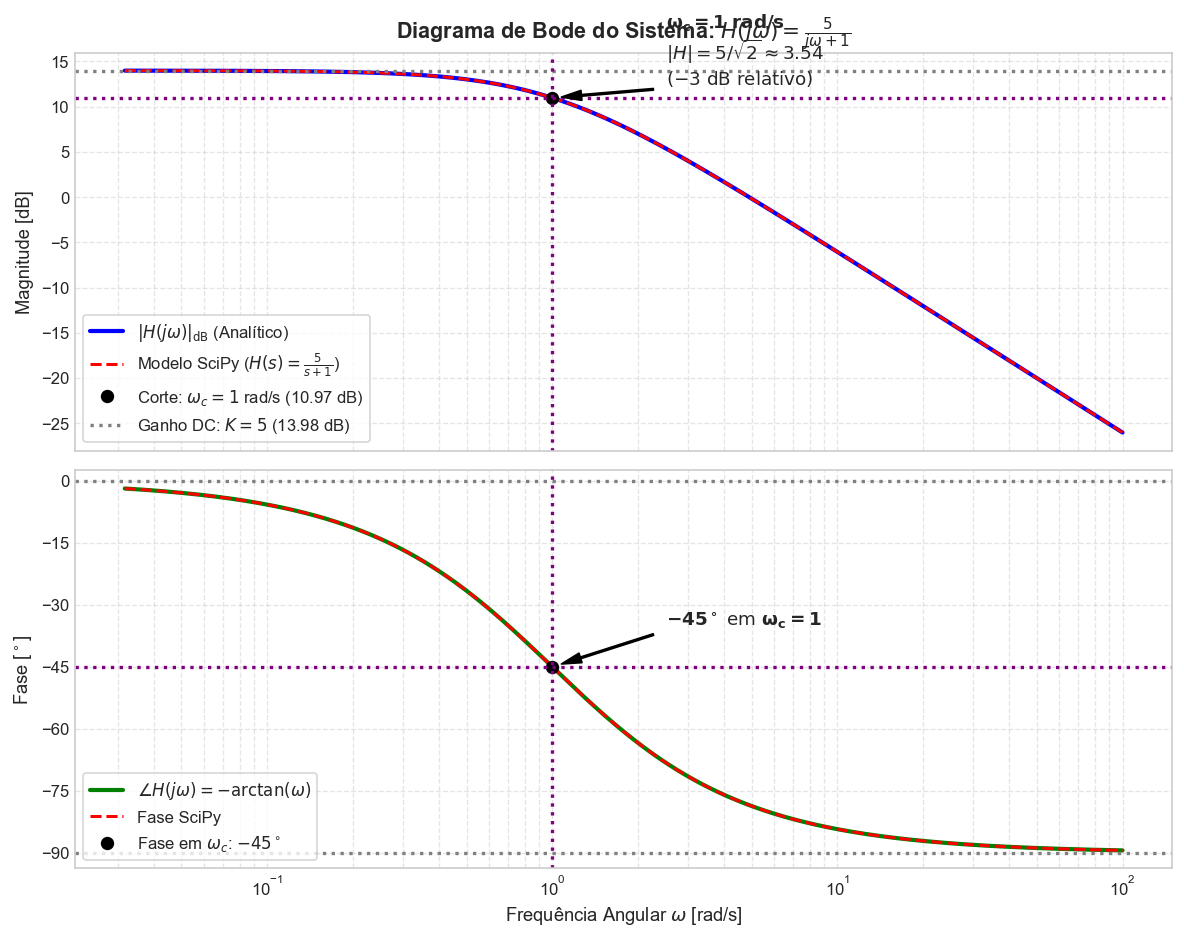

In [3]:
# ------------------------------------------------------------------------------
# Resposta em Frequência H(jw): Análise Espectral e Diagrama de Bode
# ------------------------------------------------------------------------------
# Vetor de frequências angulares (de 0.01 rad/s até 100 rad/s)
w_vec = np.logspace(-1.5, 2.0, 1000)

# Resposta em Frequência Analítica
H_analytical = 5.0 / (1.0 + 1j * w_vec)
mag_linear = np.abs(H_analytical)
mag_dB = 20 * np.log10(mag_linear)
phase_deg = np.angle(H_analytical, deg=True)
phase_rad = np.angle(H_analytical, deg=False)

# Validação com scipy.signal
sys_H = signal.TransferFunction([5], [1, 1])
w_scipy, mag_scipy, phase_scipy = signal.bode(sys_H, w=w_vec)

# Pontos notáveis
wc = 1.0  # Frequência de corte a -3 dB
H_0 = 5.0
mag_0_dB = 20 * np.log10(5.0)
mag_wc = 5.0 / np.sqrt(2.0)
mag_wc_dB = 20 * np.log10(mag_wc)
phase_wc = -45.0

fig, (ax_mag, ax_phase) = plt.subplots(2, 1, figsize=(10, 8), sharex=True)

# 1. Subplot de Magnitude (dB)
ax_mag.semilogx(w_vec, mag_dB, 'b-', label=r'$|H(j\omega)|_{\mathrm{dB}}$ (Analítico)', lw=2.5)
ax_mag.semilogx(w_scipy, mag_scipy, 'r--', label=r'Modelo SciPy ($H(s)=\frac{5}{s+1}$)', lw=1.8)
ax_mag.plot(wc, mag_wc_dB, 'ko', markersize=7, label=f'Corte: $\\omega_c=1$ rad/s ({mag_wc_dB:.2f} dB)')
ax_mag.axhline(mag_0_dB, color='gray', linestyle=':', label=f'Ganho DC: $K=5$ ({mag_0_dB:.2f} dB)')
ax_mag.axhline(mag_wc_dB, color='purple', linestyle=':')
ax_mag.axvline(wc, color='purple', linestyle=':')

ax_mag.set_title(r'Diagrama de Bode do Sistema: $H(j\omega) = \frac{5}{j\omega + 1}$', fontsize=13, fontweight='bold')
ax_mag.set_ylabel(r'Magnitude [dB]', fontsize=11)
ax_mag.legend(loc='lower left', frameon=True)
ax_mag.grid(True, which='both', ls='--', alpha=0.5)

# Anotação visual no corte
ax_mag.annotate(r'$\mathbf{\omega_c = 1\ rad/s}$' + '\n' + r'$|H| = 5/\sqrt{2} \approx 3.54$' + f'\n$(-3\\text{{ dB relativo}})$',
                xy=(wc, mag_wc_dB), xytext=(2.5, mag_wc_dB + 1.5),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

# 2. Subplot de Fase (Graus)
ax_phase.semilogx(w_vec, phase_deg, 'g-', label=r'$\angle H(j\omega) = -\arctan(\omega)$', lw=2.5)
ax_phase.semilogx(w_scipy, phase_scipy, 'r--', label=r'Fase SciPy', lw=1.8)
ax_phase.plot(wc, phase_wc, 'ko', markersize=7, label=r'Fase em $\omega_c$: $-45^\circ$')
ax_phase.axhline(0, color='gray', linestyle=':')
ax_phase.axhline(-45, color='purple', linestyle=':')
ax_phase.axhline(-90, color='gray', linestyle=':')
ax_phase.axvline(wc, color='purple', linestyle=':')

ax_phase.set_xlabel(r'Frequência Angular $\omega$ [rad/s]', fontsize=11)
ax_phase.set_ylabel(r'Fase [$^\circ$]', fontsize=11)
ax_phase.set_yticks([0, -15, -30, -45, -60, -75, -90])
ax_phase.legend(loc='lower left', frameon=True)
ax_phase.grid(True, which='both', ls='--', alpha=0.5)

ax_phase.annotate(r'$\mathbf{-45^\circ\text{ em }\omega_c=1}$',
                  xy=(wc, phase_wc), xytext=(2.5, -35),
                  arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.show()

print(f"Ganho DC (|H(j0)|): {H_0:.4f} (em dB: {mag_0_dB:.2f} dB)")
print(f"Magnitude na frequência de corte (|H(j1)|): {mag_wc:.4f} (em dB: {mag_wc_dB:.2f} dB)")
print(f"Fase na frequência de corte (arg(H(j1))): {phase_wc:.1f} graus")

Valor inicial h(0+): 5.0000
Valor em t = tau = 1 s: 1.8394 (fração 1/e do valor inicial)
Erro máximo absoluto entre analítico e numérico: 5.77e-15


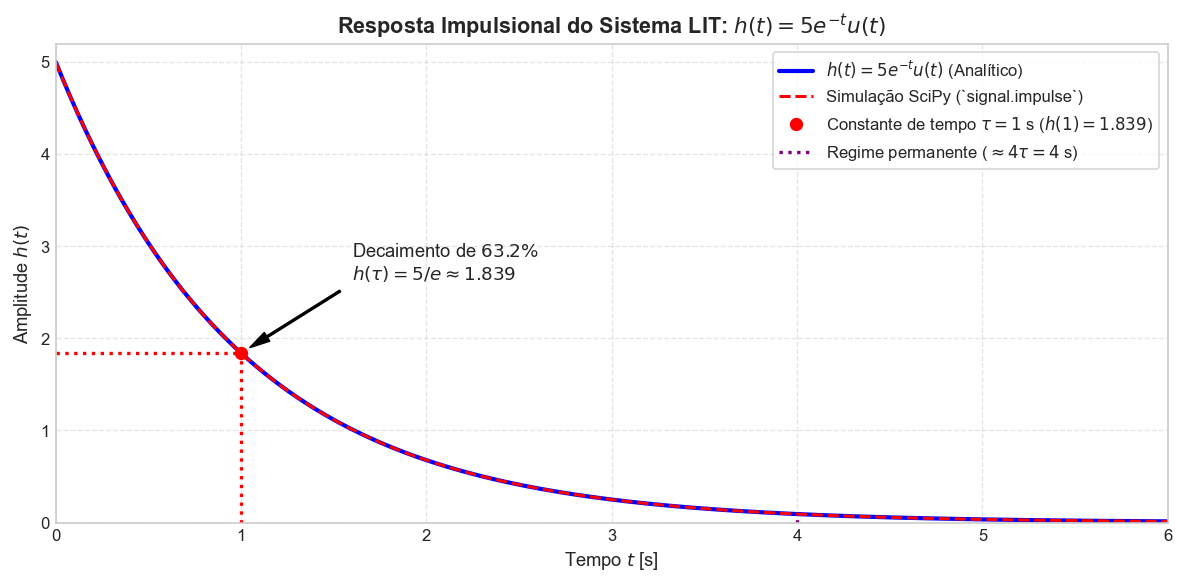

In [4]:
# ------------------------------------------------------------------------------
# Resposta Impulsional h(t): Simulação e Comparação Analítica
# ------------------------------------------------------------------------------
t_h = np.linspace(0, 6, 600)

# Expressão Analítica: h(t) = 5 * exp(-t) * u(t)
h_analytical = 5.0 * np.exp(-t_h)

# Resposta Impulsional Numérica com scipy.signal
t_scipy, h_scipy = signal.impulse(sys_H, T=t_h)

# Constante de tempo tau = 1 s
tau = 1.0
h_tau = 5.0 * np.exp(-1.0) # 5 / e ~ 1.8394 V
t_settle_2pct = 4.0 * tau   # Critério dos 2% (4 tau)

plt.figure(figsize=(10, 5))
plt.plot(t_h, h_analytical, 'b-', lw=2.5, label=r'$h(t) = 5 e^{-t} u(t)$ (Analítico)')
plt.plot(t_scipy, h_scipy, 'r--', lw=1.8, label=r'Simulação SciPy (`signal.impulse`)')

# Marcação de tau
plt.plot(tau, h_tau, 'ro', markersize=7, label=f'Constante de tempo $\\tau=1$ s ($h(1)={h_tau:.3f}$)')
plt.vlines(tau, 0, h_tau, colors='red', linestyles=':')
plt.hlines(h_tau, 0, tau, colors='red', linestyles=':')

# Marcação de 4*tau (estabilização a 2%)
plt.vlines(t_settle_2pct, 0, 5.0*np.exp(-4.0), colors='purple', linestyles=':', label=r'Regime permanente ($\approx 4\tau = 4$ s)')

plt.title(r'Resposta Impulsional do Sistema LIT: $h(t) = 5 e^{-t} u(t)$', fontsize=13, fontweight='bold')
plt.xlabel(r'Tempo $t$ [s]', fontsize=11)
plt.ylabel(r'Amplitude $h(t)$', fontsize=11)
plt.xlim([0, 6])
plt.ylim([0, 5.2])
plt.legend(loc='upper right', frameon=True)
plt.grid(True, ls='--', alpha=0.5)

plt.annotate(r'Decaimento de $63.2\%$' + '\n' + r'$h(\tau) = 5/e \approx 1.839$',
             xy=(tau, h_tau), xytext=(tau + 0.6, h_tau + 0.8),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.show()

# Teste de erro numérico máximo entre analítico e simulado
max_err_h = np.max(np.abs(h_analytical - h_scipy))
print(f"Valor inicial h(0+): {h_analytical[0]:.4f}")
print(f"Valor em t = tau = 1 s: {h_tau:.4f} (fração 1/e do valor inicial)")
print(f"Erro máximo absoluto entre analítico e numérico: {max_err_h:.2e}")

|X(j0)| = 0.40
|H(j0)| = 5.00
|Y(j0)| = 2.00 (Verificação: 0.4 * 5 = 2.0)


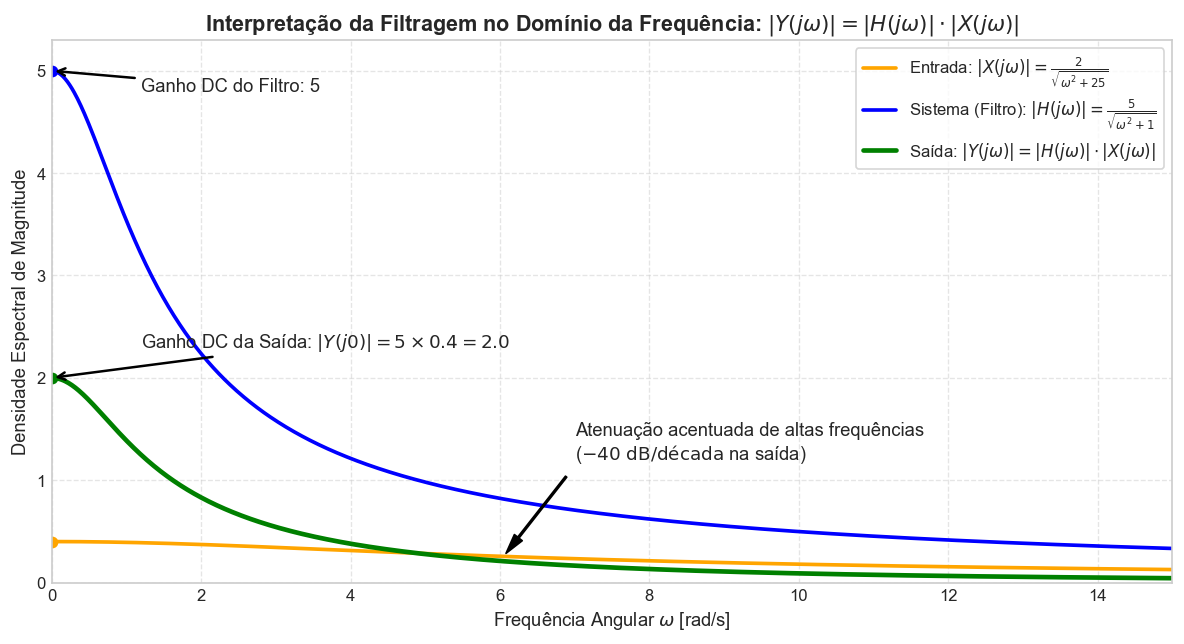

In [5]:
# ------------------------------------------------------------------------------
# Análise Espectral Cruzada: Entrada |X(jw)|, Filtro |H(jw)| e Saída |Y(jw)|
# ------------------------------------------------------------------------------
w_spec = np.linspace(0, 15, 1000)

# Espectros analíticos de magnitude
# X(jw) = 2 / (jw + 5) => |X(jw)| = 2 / sqrt(w^2 + 25)
X_mag = 2.0 / np.sqrt(w_spec**2 + 25.0)

# H(jw) = 5 / (jw + 1) => |H(jw)| = 5 / sqrt(w^2 + 1)
H_mag_lin = 5.0 / np.sqrt(w_spec**2 + 1.0)

# Y(jw) = 10 / ((jw + 1)(jw + 5)) => |Y(jw)| = 10 / sqrt((w^2 + 1)(w^2 + 25))
Y_mag = 10.0 / np.sqrt((w_spec**2 + 1.0) * (w_spec**2 + 25.0))

# Verificação: |Y| == |H| * |X|
assert np.allclose(Y_mag, X_mag * H_mag_lin), "Erro na multiplicação espectral!"

fig, ax1 = plt.subplots(figsize=(10, 5.5))

ax1.plot(w_spec, X_mag, 'orange', lw=2.2, label=r'Entrada: $|X(j\omega)| = \frac{2}{\sqrt{\omega^2 + 25}}$')
ax1.plot(w_spec, H_mag_lin, 'blue', lw=2.2, label=r'Sistema (Filtro): $|H(j\omega)| = \frac{5}{\sqrt{\omega^2 + 1}}$')
ax1.plot(w_spec, Y_mag, 'green', lw=2.8, label=r'Saída: $|Y(j\omega)| = |H(j\omega)| \cdot |X(j\omega)|$')

# Pontos DC
ax1.plot(0, 2.0/5.0, 'o', color='orange')
ax1.plot(0, 5.0, 'o', color='blue')
ax1.plot(0, 2.0, 'o', color='green')

ax1.set_title(r'Interpretação da Filtragem no Domínio da Frequência: $|Y(j\omega)| = |H(j\omega)| \cdot |X(j\omega)|$',
              fontsize=13, fontweight='bold')
ax1.set_xlabel(r'Frequência Angular $\omega$ [rad/s]', fontsize=11)
ax1.set_ylabel(r'Densidade Espectral de Magnitude', fontsize=11)
ax1.set_xlim([0, 15])
ax1.set_ylim([0, 5.3])
ax1.legend(loc='upper right', frameon=True)
ax1.grid(True, ls='--', alpha=0.5)

# Destaques explicativos
ax1.annotate('Ganho DC do Filtro: 5', xy=(0, 5.0), xytext=(1.2, 4.8),
             arrowprops=dict(arrowstyle="->", lw=1.5))
ax1.annotate(r'Ganho DC da Saída: $|Y(j0)| = 5 \times 0.4 = 2.0$', xy=(0, 2.0), xytext=(1.2, 2.3),
             arrowprops=dict(arrowstyle="->", lw=1.5))
ax1.annotate('Atenuação acentuada de altas frequências\n' + r'($-40\text{ dB/década}$ na saída)',
             xy=(6, Y_mag[np.argmin(np.abs(w_spec - 6))]), xytext=(7, 1.2),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

plt.show()

print(f"|X(j0)| = {X_mag[0]:.2f}")
print(f"|H(j0)| = {H_mag_lin[0]:.2f}")
print(f"|Y(j0)| = {Y_mag[0]:.2f} (Verificação: 0.4 * 5 = 2.0)")

RELATÓRIO DE MÉTRICAS DA RESPOSTA TEMPORAL
Condição inicial: y(0+) = 0.000000 V
Instante do pico máximo analítico: t_max = ln(5)/4 = 0.40236 s
Instante do pico máximo numérico : t_num = 0.40270 s
Amplitude máxima analítica       : y_max = 1.33748 V
Amplitude máxima numérica        : y_num = 1.33750 V
Erro máximo absoluto (lsim)      : 1.74e-05
Erro máximo absoluto (convolução): 2.50e-02


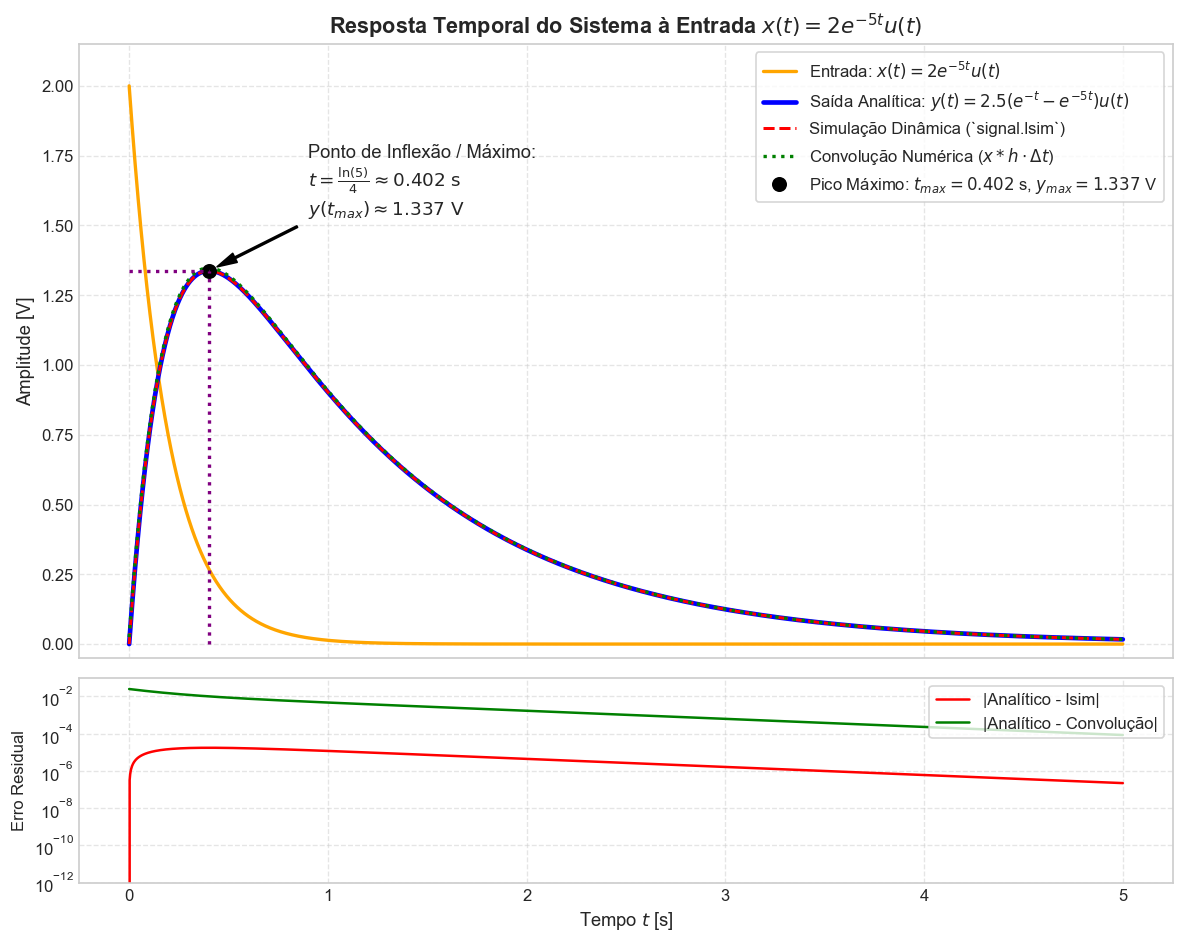

In [6]:
# ------------------------------------------------------------------------------
# Resposta Temporal y(t): Validação Cruzada entre 3 Métodos
# 1) Solução Analítica Exata
# 2) Simulação Dinâmica com scipy.signal.lsim
# 3) Convolução Numérica Direta: y_num = x * h * dt
# ------------------------------------------------------------------------------
# Grelha temporal de alta densidade
t_vec = np.linspace(0, 5, 2000)
dt = t_vec[1] - t_vec[0]

# 1) Solução Analítica Exata
x_exact = 2.0 * np.exp(-5.0 * t_vec)
y_exact = 2.5 * (np.exp(-t_vec) - np.exp(-5.0 * t_vec))

# Cálculo dos valores extremos analíticos
t_max_analytic = np.log(5.0) / 4.0
y_max_analytic = 2.5 * (np.exp(-t_max_analytic) - np.exp(-5.0 * t_max_analytic))

# 2) Simulação Dinâmica com SciPy (lsim)
# H(s) = 5 / (s + 1)
tout, y_lsim, _ = signal.lsim(sys_H, U=x_exact, T=t_vec)

# 3) Convolução Numérica Direta (y = x * h * dt)
h_conv = 5.0 * np.exp(-t_vec)
y_conv_full = np.convolve(x_exact, h_conv) * dt
y_conv = y_conv_full[:len(t_vec)]

# Visualização Gráfica
fig, (ax_sig, ax_res) = plt.subplots(2, 1, figsize=(10, 8), sharex=True,
                                     gridspec_kw={'height_ratios': [3, 1]})

# Subplot Superior: Sinais de Entrada e de Saída
ax_sig.plot(t_vec, x_exact, 'orange', lw=2.0, label=r'Entrada: $x(t) = 2e^{-5t}u(t)$')
ax_sig.plot(t_vec, y_exact, 'b-', lw=2.8, label=r'Saída Analítica: $y(t) = 2.5(e^{-t} - e^{-5t})u(t)$')
ax_sig.plot(tout, y_lsim, 'r--', lw=1.8, label=r'Simulação Dinâmica (`signal.lsim`)')
ax_sig.plot(t_vec, y_conv, 'g:', lw=2.0, label=r'Convolução Numérica ($x * h \cdot \Delta t$)')

# Destaque do Ponto de Máximo
ax_sig.plot(t_max_analytic, y_max_analytic, 'ko', markersize=8,
            label=f'Pico Máximo: $t_{{max}}={t_max_analytic:.3f}$ s, $y_{{max}}={y_max_analytic:.3f}$ V')
ax_sig.vlines(t_max_analytic, 0, y_max_analytic, colors='purple', linestyles=':')
ax_sig.hlines(y_max_analytic, 0, t_max_analytic, colors='purple', linestyles=':')

ax_sig.set_title(r'Resposta Temporal do Sistema à Entrada $x(t) = 2e^{-5t}u(t)$', fontsize=13, fontweight='bold')
ax_sig.set_ylabel(r'Amplitude [V]', fontsize=11)
ax_sig.set_ylim([-0.05, 2.15])
ax_sig.legend(loc='upper right', frameon=True)
ax_sig.grid(True, ls='--', alpha=0.5)

ax_sig.annotate(f'Ponto de Inflexão / Máximo:\n$t = \\frac{{\\ln(5)}}{{4}} \\approx {t_max_analytic:.3f}\\text{{ s}}$\n$y(t_{{max}}) \\approx {y_max_analytic:.3f}\\text{{ V}}$',
                xy=(t_max_analytic, y_max_analytic),
                xytext=(t_max_analytic + 0.5, y_max_analytic + 0.2),
                arrowprops=dict(facecolor='black', shrink=0.08, width=1, headwidth=6))

# Subplot Inferior: Erro Numérico Residual (Analítico vs Numérico)
err_lsim = np.abs(y_exact - y_lsim)
err_conv = np.abs(y_exact - y_conv)

ax_res.plot(t_vec, err_lsim, 'r-', lw=1.5, label='|Analítico - lsim|')
ax_res.plot(t_vec, err_conv, 'g-', lw=1.5, label='|Analítico - Convolução|')
ax_res.set_xlabel(r'Tempo $t$ [s]', fontsize=11)
ax_res.set_ylabel(r'Erro Residual', fontsize=10)
ax_res.set_yscale('log')
ax_res.set_ylim([1e-12, 1e-1])
ax_res.legend(loc='upper right', frameon=True)
ax_res.grid(True, which='both', ls='--', alpha=0.5)

plt.show()

print("="*65)
print("RELATÓRIO DE MÉTRICAS DA RESPOSTA TEMPORAL")
print("="*65)
print(f"Condição inicial: y(0+) = {y_exact[0]:.6f} V")
print(f"Instante do pico máximo analítico: t_max = ln(5)/4 = {t_max_analytic:.5f} s")
print(f"Instante do pico máximo numérico : t_num = {t_vec[np.argmax(y_lsim)]:.5f} s")
print(f"Amplitude máxima analítica       : y_max = {y_max_analytic:.5f} V")
print(f"Amplitude máxima numérica        : y_num = {np.max(y_lsim):.5f} V")
print(f"Erro máximo absoluto (lsim)      : {np.max(err_lsim):.2e}")
print(f"Erro máximo absoluto (convolução): {np.max(err_conv):.2e}")

CONCLUSÃO DO ESTUDO PARAMÉTRICO:
1. À medida que o polo se afasta da origem para a esquerda (polo mais negativo, p aumenta):
   - A largura de banda do filtro aumenta (omega_c cresce);
   - A resposta temporal torna-se significativamente mais rápida (tempo de subida menor);
   - O pico atinge amplitudes maiores devido à menor atenuação da dinâmica rápida da entrada.


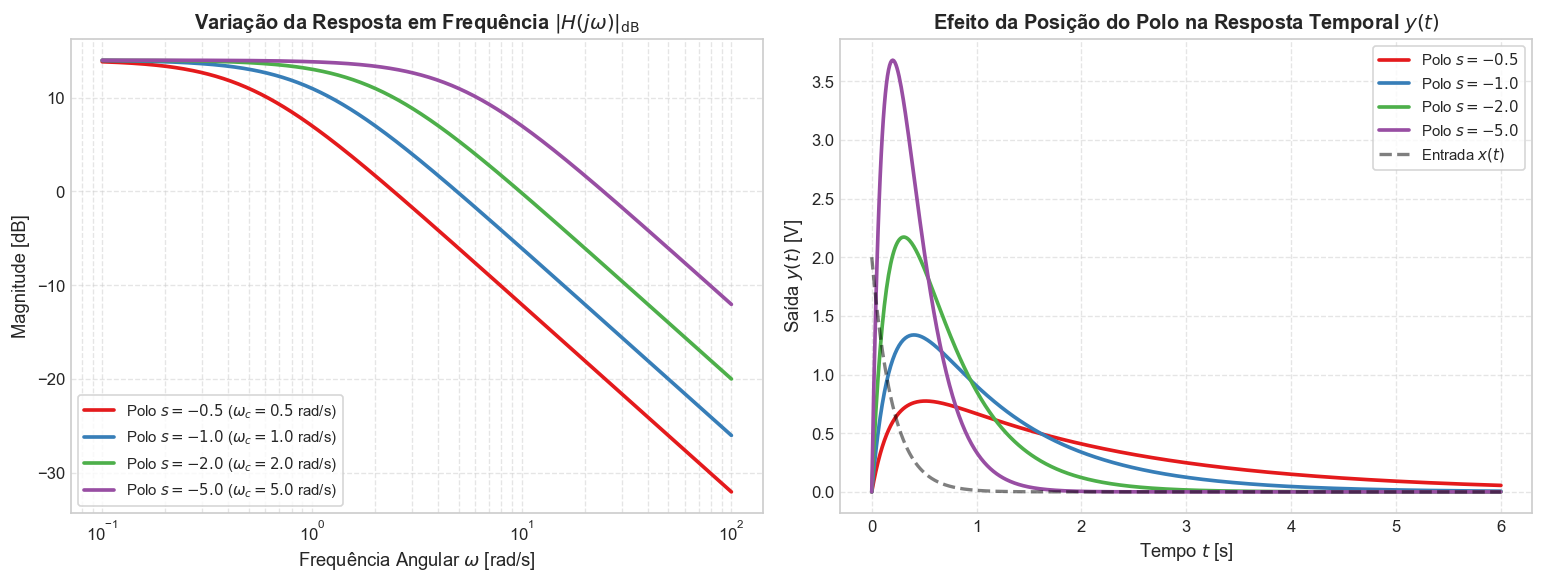

In [7]:
# ------------------------------------------------------------------------------
# Análise de Sensibilidade Paramétrica: Variação da Posição do Polo
# Sistema: dy/dt + p*y = 5*p*x(t)  <=>  H(s) = 5*p / (s + p) (mantendo ganho DC = 5)
# ------------------------------------------------------------------------------
polos = [0.5, 1.0, 2.0, 5.0]
cores = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

fig, (ax_p_freq, ax_p_time) = plt.subplots(1, 2, figsize=(13, 5))

w_range = np.logspace(-1, 2, 500)
t_range = np.linspace(0, 6, 600)
x_in = 2.0 * np.exp(-5.0 * t_range)

for p, col in zip(polos, cores):
    # Função de transferência com ganho DC = 5: H(s) = 5*p / (s + p)
    sys_p = signal.TransferFunction([5.0 * p], [1.0, p])
    
    # 1. Resposta em Frequência (Bode Magnitude)
    _, mag_p, _ = signal.bode(sys_p, w=w_range)
    ax_p_freq.semilogx(w_range, mag_p, color=col, lw=2.2, label=f'Polo $s = -{p}$ ($\\omega_c = {p}$ rad/s)')
    
    # 2. Resposta Temporal à entrada x(t) = 2*exp(-5t)*u(t)
    _, y_p, _ = signal.lsim(sys_p, U=x_in, T=t_range)
    ax_p_time.plot(t_range, y_p, color=col, lw=2.2, label=f'Polo $s = -{p}$')

# Configuração do gráfico de magnitude
ax_p_freq.set_title(r'Variação da Resposta em Frequência $|H(j\omega)|_{\mathrm{dB}}$', fontsize=12, fontweight='bold')
ax_p_freq.set_xlabel(r'Frequência Angular $\omega$ [rad/s]', fontsize=11)
ax_p_freq.set_ylabel(r'Magnitude [dB]', fontsize=11)
ax_p_freq.legend(frameon=True, fontsize=9)
ax_p_freq.grid(True, which='both', ls='--', alpha=0.5)

# Configuração do gráfico temporal
ax_p_time.plot(t_range, x_in, 'k--', alpha=0.5, label='Entrada $x(t)$')
ax_p_time.set_title(r'Efeito da Posição do Polo na Resposta Temporal $y(t)$', fontsize=12, fontweight='bold')
ax_p_time.set_xlabel(r'Tempo $t$ [s]', fontsize=11)
ax_p_time.set_ylabel(r'Saída $y(t)$ [V]', fontsize=11)
ax_p_time.legend(frameon=True, fontsize=9)
ax_p_time.grid(True, ls='--', alpha=0.5)

plt.show()

print("CONCLUSÃO DO ESTUDO PARAMÉTRICO:")
print("1. À medida que o polo se afasta da origem para a esquerda (polo mais negativo, p aumenta):")
print("   - A largura de banda do filtro aumenta (omega_c cresce);")
print("   - A resposta temporal torna-se significativamente mais rápida (tempo de subida menor);")
print("   - O pico atinge amplitudes maiores devido à menor atenuação da dinâmica rápida da entrada.")